In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestRegressor 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [2]:
df = pd.read_csv("./Downloads/diem_thi_thpt_2024.csv", dtype = {'sbd': str})
df.head()

,sbd,toan,ngu_van,ngoai_ngu,vat_li,hoa_hoc,sinh_hoc,lich_su,dia_li,gdcd,ma_ngoai_ngu
0,01000001,8.4,6.75,8.0,6.0,5.25,5.0,NaN,NaN,NaN,N1
1,01000002,8.6,8.50,7.2,NaN,NaN,NaN,7.25,6.00,8.00,N1
2,01000003,8.2,8.75,8.2,NaN,NaN,NaN,7.25,7.25,8.75,N1
3,01000004,4.8,8.50,7.4,NaN,NaN,NaN,7.00,6.00,7.50,N1
4,01000005,8.6,9.00,7.8,NaN,NaN,NaN,9.00,8.75,8.50,N1


In [3]:
df.isnull().sum()

sbd                  0
toan             15992
ngu_van          11504
ngoai_ngu       148900
vat_li          715990
hoa_hoc         715087
sinh_hoc        719227
lich_su         355391
dia_li          356923
gdcd            477996
ma_ngoai_ngu    148900
dtype: int64

In [4]:
df_clean = df.fillna(-1)
pd.options.display.float_format = '{:.2f}'.format
df_clean

,sbd,toan,ngu_van,ngoai_ngu,vat_li,hoa_hoc,sinh_hoc,lich_su,dia_li,gdcd,ma_ngoai_ngu
0,01000001,8.40,6.75,8.00,6.00,5.25,5.00,-1.00,-1.00,-1.00,N1
1,01000002,8.60,8.50,7.20,-1.00,-1.00,-1.00,7.25,6.00,8.00,N1
2,01000003,8.20,8.75,8.20,-1.00,-1.00,-1.00,7.25,7.25,8.75,N1
3,01000004,4.80,8.50,7.40,-1.00,-1.00,-1.00,7.00,6.00,7.50,N1
4,01000005,8.60,9.00,7.80,-1.00,-1.00,-1.00,9.00,8.75,8.50,N1
...,...,...,...,...,...,...,...,...,...,...,...
1061600,64007282,4.20,6.00,3.00,-1.00,-1.00,-1.00,5.25,6.25,7.50,N1
1061601,64007283,5.20,6.00,3.60,-1.00,-1.00,-1.00,6.25,5.75,7.75,N1
1061602,64007284,7.20,8.00,7.00,6.25,7.00,8.00,-1.00,-1.00,-1.00,N1
1061603,64007285,5.20,5.25,4.40,-1.00,-1.00,-1.00,4.75,6.50,8.75,N1


KHOI A00

In [5]:
df_A00 = df_clean[(df_clean['toan'] != -1) & (df_clean['vat_li'] != -1) & (df_clean['hoa_hoc'] != -1)]
df_A00.drop(columns = ['ngu_van', 'ngoai_ngu', 'lich_su', 'dia_li', 'gdcd', 'ma_ngoai_ngu', 'sinh_hoc'])

,sbd,toan,vat_li,hoa_hoc
0,01000001,8.40,6.00,5.25
8,01000009,8.20,8.25,4.25
10,01000011,7.20,7.75,6.75
16,01000017,7.00,3.75,7.50
17,01000018,8.20,7.75,6.75
...,...,...,...,...
1061589,64007271,7.80,7.50,7.00
1061590,64007272,6.80,6.25,7.25
1061592,64007274,7.00,3.00,6.25
1061599,64007281,6.40,5.75,4.50


In [6]:
df_A00.count()

sbd             343800
toan            343800
ngu_van         343800
ngoai_ngu       343800
vat_li          343800
hoa_hoc         343800
sinh_hoc        343800
lich_su         343800
dia_li          343800
gdcd            343800
ma_ngoai_ngu    343800
dtype: int64

In [7]:
df_A00['Tong_diem_A00'] = df_A00['toan'] + df_A00['vat_li'] + df_A00['hoa_hoc']
df_A00

C:\Users\admin\AppData\Local\Temp\ipykernel_11196\4169073438.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_A00['Tong_diem_A00'] = df_A00['toan'] + df_A00['vat_li'] + df_A00['hoa_hoc']


,sbd,toan,ngu_van,ngoai_ngu,vat_li,hoa_hoc,sinh_hoc,lich_su,dia_li,gdcd,ma_ngoai_ngu,Tong_diem_A00
0,01000001,8.40,6.75,8.00,6.00,5.25,5.00,-1.00,-1.00,-1.00,N1,19.65
8,01000009,8.20,8.00,8.60,8.25,4.25,6.00,-1.00,-1.00,-1.00,N1,20.70
10,01000011,7.20,8.50,9.00,7.75,6.75,6.25,-1.00,-1.00,-1.00,N1,21.70
16,01000017,7.00,8.75,7.80,3.75,7.50,7.25,-1.00,-1.00,-1.00,N1,18.25
17,01000018,8.20,6.00,9.00,7.75,6.75,6.75,-1.00,-1.00,-1.00,N1,22.70
...,...,...,...,...,...,...,...,...,...,...,...,...
1061589,64007271,7.80,6.50,5.20,7.50,7.00,5.75,-1.00,-1.00,-1.00,N1,22.30
1061590,64007272,6.80,7.25,5.80,6.25,7.25,7.00,-1.00,-1.00,-1.00,N1,20.30
1061592,64007274,7.00,7.50,5.00,3.00,6.25,6.00,-1.00,-1.00,-1.00,N1,16.25
1061599,64007281,6.40,7.25,3.80,5.75,4.50,4.25,-1.00,-1.00,-1.00,N1,16.65


In [8]:
print(f"Diem cua thu khoa: {df_A00['Tong_diem_A00'].max()}")

Diem cua thu khoa: 29.6


In [9]:
top_5 = df_A00.sort_values(by = 'Tong_diem_A00', ascending= False)
top_5[['sbd','toan', 'vat_li', 'hoa_hoc', 'Tong_diem_A00']].head()

,sbd,toan,vat_li,hoa_hoc,Tong_diem_A00
509412,26020938,9.60,10.00,10.00,29.60
498487,26009943,9.80,9.75,10.00,29.55
406704,19016615,9.60,9.75,10.00,29.35
503248,26014736,9.80,9.50,10.00,29.30
403266,19013166,9.80,9.75,9.75,29.30


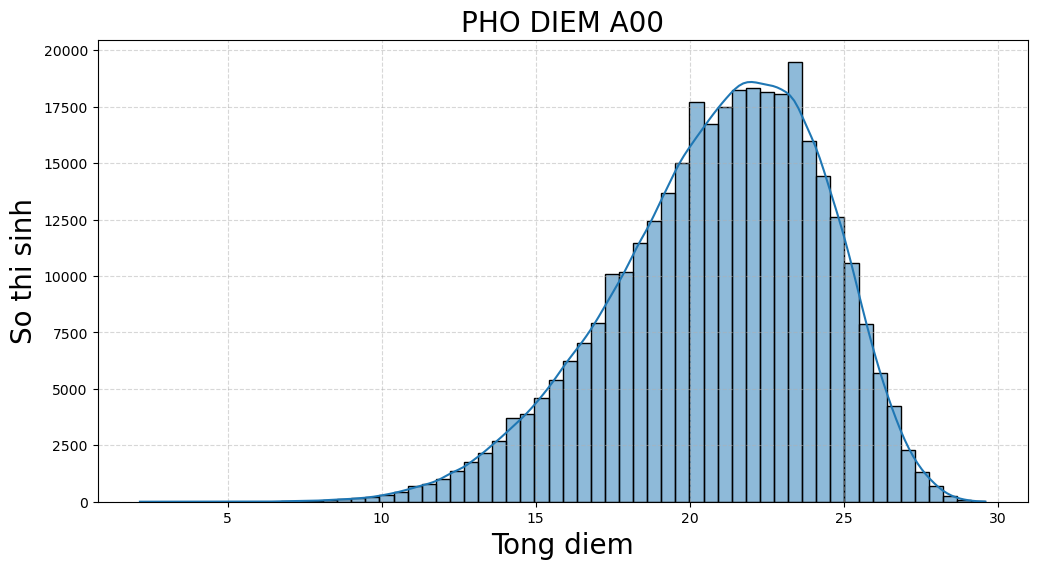

In [10]:
plt.figure(figsize = (12,6))
plt.grid(linestyle='--', alpha=0.5)
plt.title('PHO DIEM A00', fontsize = 20)
plt.xlabel('Tong diem', fontsize = 20)
plt.ylabel('So thi sinh', fontsize = 20)
sns.histplot(data = df_A00['Tong_diem_A00'],bins = 60, kde = True);
plt.show()

KHOI B00

In [11]:
df_B00 = df_clean[(df_clean['toan'] != -1) & (df_clean['hoa_hoc'] != -1) & (df_clean['sinh_hoc'] != -1)]
df_B00_new = df_B00.drop(columns= ['ngu_van', 'ngoai_ngu', 'vat_li', 'lich_su', 'dia_li', 'gdcd', 'ma_ngoai_ngu'])
df_B00_new

,sbd,toan,hoa_hoc,sinh_hoc
0,01000001,8.40,5.25,5.00
8,01000009,8.20,4.25,6.00
10,01000011,7.20,6.75,6.25
16,01000017,7.00,7.50,7.25
17,01000018,8.20,6.75,6.75
...,...,...,...,...
1061589,64007271,7.80,7.00,5.75
1061590,64007272,6.80,7.25,7.00
1061592,64007274,7.00,6.25,6.00
1061599,64007281,6.40,4.50,4.25


In [12]:
df_B00_new['Tong_diem_B00'] = df_B00_new['toan'] + df_B00_new['sinh_hoc'] + df_B00_new['hoa_hoc']
df_B00_new

,sbd,toan,hoa_hoc,sinh_hoc,Tong_diem_B00
0,01000001,8.40,5.25,5.00,18.65
8,01000009,8.20,4.25,6.00,18.45
10,01000011,7.20,6.75,6.25,20.20
16,01000017,7.00,7.50,7.25,21.75
17,01000018,8.20,6.75,6.75,21.70
...,...,...,...,...,...
1061589,64007271,7.80,7.00,5.75,20.55
1061590,64007272,6.80,7.25,7.00,21.05
1061592,64007274,7.00,6.25,6.00,19.25
1061599,64007281,6.40,4.50,4.25,15.15


In [13]:
top_5_B00 = df_B00_new.sort_values(by = 'Tong_diem_B00', ascending= False)
top_5_B00.head()

,sbd,toan,hoa_hoc,sinh_hoc,Tong_diem_B00
210905,03015805,9.80,10.00,9.75,29.55
794164,44002862,9.40,10.00,10.00,29.40
318996,15000286,9.40,10.00,10.00,29.40
565070,29003629,9.40,10.00,10.00,29.40
990049,56010544,9.60,10.00,9.75,29.35


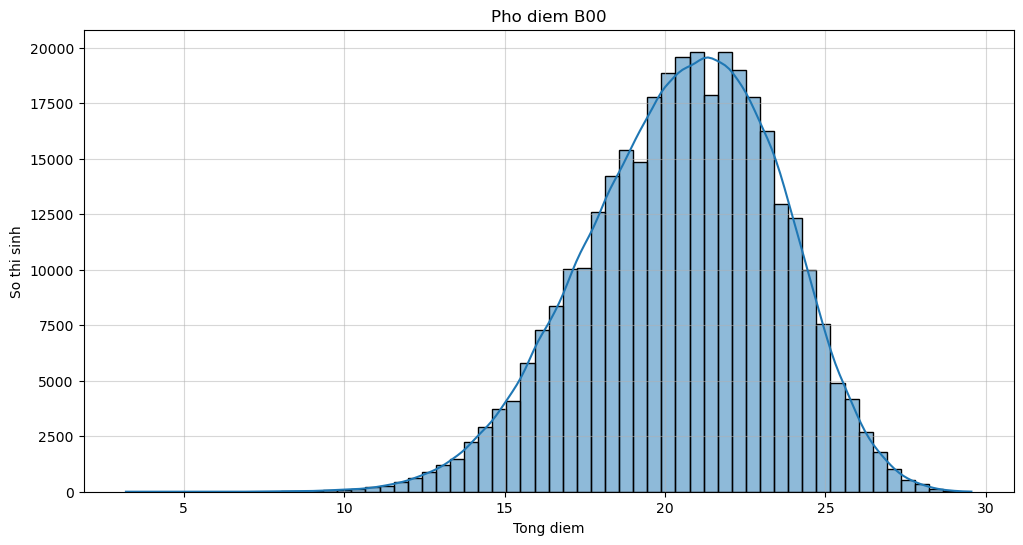

In [14]:
plt.figure(figsize = (12,6));
sns.histplot(data = df_B00_new['Tong_diem_B00'], bins = 60, kde = True);
plt.xlabel('Tong diem')
plt.ylabel('So thi sinh')
plt.title('Pho diem B00')
plt.grid(visible = None, alpha = 0.5)
plt.show()

Dùng điểm toán, lý để dự đoán điểm hóa

In [15]:
X = df_A00[['toan', 'vat_li']]
y = df_A00['hoa_hoc']


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state= 42)
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
sai_so = mean_absolute_error(y_test, y_pred)

hs_moi = [[9.0, 8]]
du_doan = model.predict(hs_moi)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [17]:
print(sai_so)

1.156521074781875


In [18]:
print(du_doan)

[7.81850674]


In [19]:
y_test

903244    7.00
957920    5.75
1031457   7.75
637055    9.00
803635    7.75
          ... 
509347    9.25
946253    8.75
841246    6.75
435514    9.75
1036806   5.50
Name: hoa_hoc, Length: 68760, dtype: float64

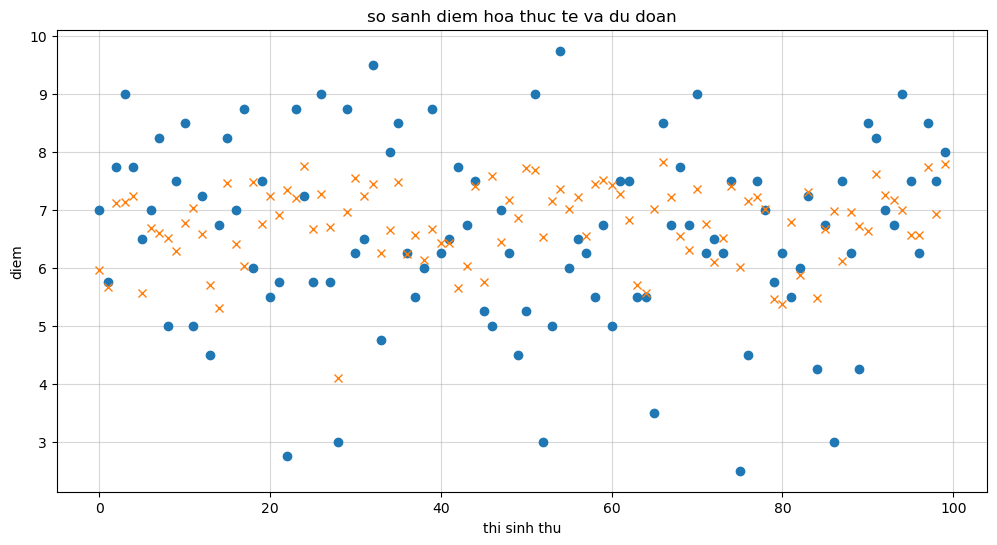

In [20]:
plt.figure(figsize = (12,6))
plt.plot(y_test.values[:100],label = 'diem hoa thuc te', marker = 'o', linestyle = '')
plt.plot(y_pred[:100], label = 'diem hoa du doan', marker = 'x', linestyle = '')
plt.title('so sanh diem hoa thuc te va du doan')
plt.xlabel('thi sinh thu')
plt.ylabel('diem')
plt.grid(alpha = 0.5)
plt.show()

In [21]:
model_rf = RandomForestRegressor(random_state = 42)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)
print(mean_absolute_error(y_test, y_pred_rf))

1.1463942242558063


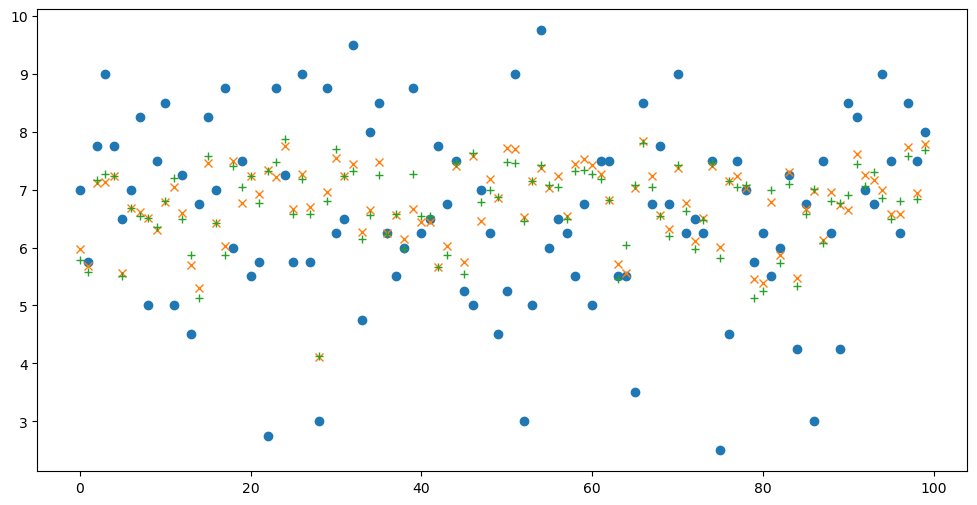

In [22]:
plt.figure(figsize = (12,6))
plt.plot(y_test.values[:100], marker = 'o', linestyle = '')
plt.plot(y_pred[:100], marker = 'x', linestyle = '')
plt.plot(y_pred_rf[:100], marker = '+', linestyle = '')

BÀI TOÁN PHÂN LOẠI

In [23]:
df_A00['tong_diem'] = df_A00['toan'] + df_A00['vat_li'] + df_A00['hoa_hoc']
X = df_A00[['toan', 'vat_li']]
y = (df_A00['tong_diem'] >= 24.0).astype(int)
print(y.value_counts())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

tong_diem
0    278438
1     65362
Name: count, dtype: int64


C:\Users\admin\AppData\Local\Temp\ipykernel_11196\1907794596.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_A00['tong_diem'] = df_A00['toan'] + df_A00['vat_li'] + df_A00['hoa_hoc']


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [25]:
model_clf = LogisticRegression()
model_clf.fit(X_train, y_train)
y_pred_clf = model_clf.predict(X_test)
acc = accuracy_score(y_test, y_pred_clf)
print(f"Do chinh xac cua AI: {acc * 100:.2f}%")

Do chinh xac cua AI: 87.89%


In [26]:
hs_moi = pd.DataFrame([[8.5, 8.0]], columns= ['toan', 'vat_li'])
ket_qua = model_clf.predict(hs_moi)[0]
xac_suat = model_clf.predict_proba(hs_moi)[0]
print(ket_qua)
print(xac_suat)
print(f"Xac suat KHONG DAT: {xac_suat[0]*100:.2f}%")
print(f"Xac suat Dat: {xac_suat[1]*100:.2f}%")
if ket_qua == 1:
    print('Ket luan: DAT')
else:
    print('Ket luan: KO DAT')

1
[0.46131778 0.53868222]
Xac suat KHONG DAT: 46.13%
Xac suat Dat: 53.87%
Ket luan: DAT


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [28]:
model_rfc = RandomForestClassifier(n_estimators= 100, random_state= 42)
model_rfc.fit(X_train, y_train)
y_pred_rfc = model_rfc.predict(X_test)
acc_rfc = accuracy_score(y_test, y_pred_rfc)
print(f'Do chinh xac: {acc_rfc * 100 :.2f}%')

Do chinh xac: 88.37%


In [29]:
hs_moi = pd.DataFrame([[8.5, 8.0]], columns= ['toan', 'vat_li'])
ket_qua_rfc = model_rfc.predict(hs_moi)[0]
xac_suat_rfc = model_rfc.predict_proba(hs_moi)[0]
print(f'Xac suat khong dat: {xac_suat_rfc[0]*100:.2f}%')
print(f'Xac suat dat: {xac_suat_rfc[1]*100:.2f}%')
if ket_qua_rfc == 1:
    print('DAT')
else:
    print('Ko dat')

Xac suat khong dat: 49.28%
Xac suat dat: 50.72%
DAT


Feature Engineering

In [30]:
X_train_new = X_train.copy()
X_test_new = X_test.copy()

X_train_new['tong_2_mon'] = X_train_new['toan'] + X_train_new['vat_li']
X_test_new['tong_2_mon'] = X_test_new['toan'] + X_test_new['vat_li']
model_rfc_new = RandomForestClassifier(n_estimators=100, random_state=42)
model_rfc_new.fit(X_train_new, y_train)
y_pred_new = model_rfc_new.predict(X_test_new)
acc_new = accuracy_score(y_pred_new, y_test)
print(f"{acc_new*100:.2f}%")

88.37%


In [31]:

hs_moi_new = pd.DataFrame([[8.5, 8.0, 8.5 + 8.0]], columns=['toan', 'vat_li', 'tong_2_mon'])

ket_qua = model_rfc_new.predict(hs_moi_new)[0]
xac_suat = model_rfc_new.predict_proba(hs_moi_new)[0]

print(f"\nXác suất KHÔNG ĐẠT: {xac_suat[0]*100:.2f}%")
print(f"Xác suất ĐẠT: {xac_suat[1]*100:.2f}%")
print(f"Kết luận: {'ĐẠT' if ket_qua == 1 else 'KHÔNG ĐẠT'}")


Xác suất KHÔNG ĐẠT: 44.72%
Xác suất ĐẠT: 55.28%
Kết luận: ĐẠT


In [32]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable


In [33]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

model_xgb = XGBClassifier(n_estimators = 100, learning_rate = 0.05, max_depth = 4, random_state = 42)
model_xgb.fit(X_train, y_train)
y_pred_xgb = model_xgb.predict(X_test)
acc_xgb = accuracy_score(y_pred_xgb, y_test)
print(f"{acc_xgb*100:.2f}%")

88.36%


In [34]:
ket_qua_xgb = model_xgb.predict(hs_moi)[0]
xac_suat_xgb = model_xgb.predict_proba(hs_moi)[0]
print(f"Xac suat KO DAT: {xac_suat_xgb[0]*100:.2f}%")
print(f"Xac suat DAT: {xac_suat_xgb[1]*100:.2f}%")
print("DAT" if ket_qua_xgb == 1 else "KO DAT")

Xac suat KO DAT: 49.26%
Xac suat DAT: 50.74%
DAT


GridSearchCV - Tự động tinh chỉnh tham số

In [39]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
param_grid = {
    'n_estimators' : [50,100, 150],
    'max_depth' : [3,4,6],
    'learning_rate' : [0.01, 0.05, 0.1]
}

xgb_base = XGBClassifier(random_state = 42)
grid_search = GridSearchCV(
    estimator= xgb_base,
    param_grid = param_grid,
    cv = 3,
    scoring = 'accuracy',
    n_jobs = -1,
    verbose = 1
)
grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 27 candidates, totalling 81 fits


,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [40]:
print(grid_search.best_params_)
print(f"{grid_search.best_score_*100:.2f}%")
best_xgb = grid_search.best_estimator_
y_pred_best = best_xgb.predict(X_test)
acc_best = accuracy_score(y_pred_best, y_test)
print(f"{acc_best*100:.2f}%")

{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 50}
88.25%
88.36%


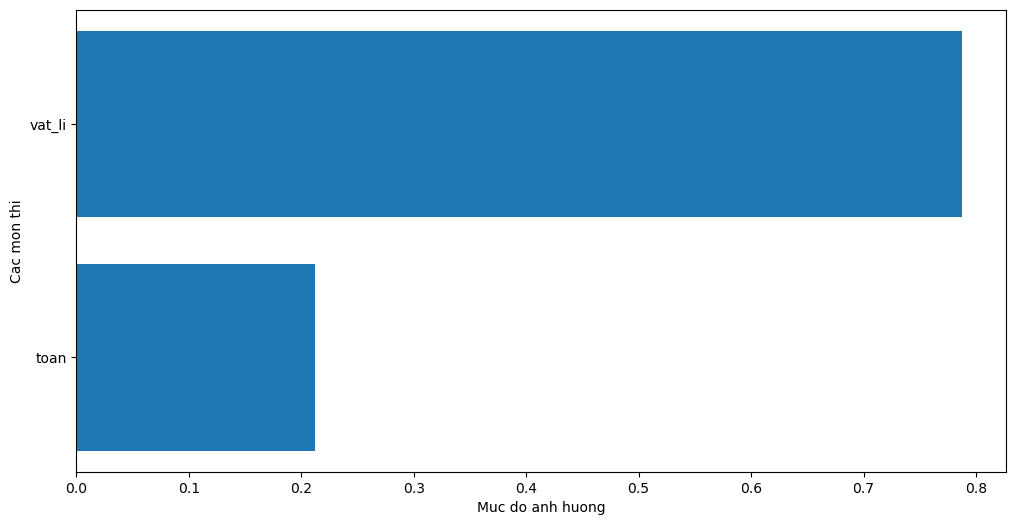

In [51]:
muc_do_quan_trong = best_xgb.feature_importances_
ten_mon_hoc = X_train.columns
df_quan_trong = pd.DataFrame({
    'Mon thi' : ten_mon_hoc,
    'Do quan trong': muc_do_quan_trong
})
df_quan_trong = df_quan_trong.sort_values(by = 'Do quan trong', ascending = True)
plt.figure(figsize=(12,6))
plt.xlabel('Muc do anh huong')
plt.ylabel('Cac mon thi')
plt.barh(df_quan_trong['Mon thi'], df_quan_trong['Do quan trong'])
plt.show()

Confusion Matrix

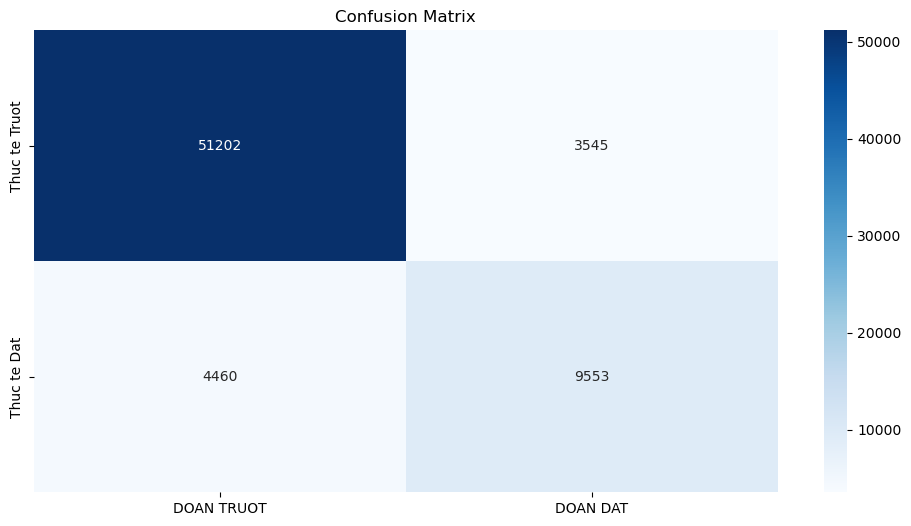

In [61]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_du_doan = best_xgb.predict(X_test)
ma_tran = confusion_matrix(y_du_doan, y_test)
plt.figure(figsize = (12,6))
sns.heatmap(ma_tran, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels= ['DOAN TRUOT', 'DOAN DAT'], yticklabels= ['Thuc te Truot', 'Thuc te Dat']
           )
plt.title('Confusion Matrix')
plt.show()